# Soil Type Classification with PyTorch and Roboflow

In [1]:
!pip install roboflow torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.9/276.9 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 37.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 83.5 MB/s eta 0:00:00:00:01
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92


In [2]:
!pip install seaborn scikit-learn matplotlib pillow

## Download and Load Roboflow Dataset
Use the Roboflow API to download the dataset folder.

In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("saas-z6xqj").project("soil-classification-ocde8-jt7ad")
version = project.version(3)
dataset = version.download("folder")
                
print("Downloaded dataset to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Soil-Type-Identification-1 in folder:: 100%|██████████| 4222/4222 [00:00<00:00, 5099.13it/s]


Downloaded dataset to: /kaggle/working/Soil-Type-Identification-1


## Inspect Dataset Paths and Counts
Check the train, valid, and test split folders and confirm they exist.


In [ ]:
import os
from pathlib import Path

root = Path(dataset.location)
train_dir = root / "train"
valid_dir = root / "valid"
test_dir = root / "test"

for split in [train_dir, valid_dir, test_dir]:
    print(f"{split.name}: {split} | exists: {split.exists()}")

train: /kaggle/working/Soil-Type-Identification-1/train | exists: True
valid: /kaggle/working/Soil-Type-Identification-1/valid | exists: True
test: /kaggle/working/Soil-Type-Identification-1/test | exists: True


## Set Hyperparameters
Define batch size, image size, and worker settings for data loading.


In [ ]:
batch_size = 16
image_size = 224
num_workers = 0 if os.name == "nt" else 4
num_epochs = 15

print("batch_size =", batch_size)
print("image_size =", image_size)
print("num_workers =", num_workers)
print("num_epochs =", num_epochs)

batch_size = 32
image_size = 224
num_workers = 4
num_epochs = 15


## Define Image Transforms and DataLoaders
Create simple transforms for training and validation/test data.


In [6]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize(image_size),
    # transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    # transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [8]:
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
valid_dataset = datasets.ImageFolder(valid_dir, transform=val_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

In [9]:
print("Classes:", train_dataset.classes)
print("Train samples:", len(train_dataset))
print("Valid samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))

Classes: ['Black Soil', 'Cinder Soil', 'Laterite Soil', 'Peat Soil', 'Yellow Soil']
Train samples: 3570
Valid samples: 428
Test samples: 204


## Build a Pretrained CNN Model
Use a single strong model: ResNet-50 with a new output layer.


In [10]:
import torch.nn as nn
from torchvision import models

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [12]:
num_classes = len(train_dataset.classes)
model = models.resnet50(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)

The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 217MB/s]


In [ ]:
print(model)

## Train the Model
Train for a few epochs using the training DataLoader.


In [13]:
from tqdm.notebook import tqdm

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc="Evaluating", leave=False):
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

In [14]:
from tqdm.notebook import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(loader, desc="Training", leave=False):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [15]:
for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    valid_loss, valid_acc = evaluate(model, valid_loader, criterion, device)

    print(f"Epoch {epoch+1}: train loss={train_loss:.4f}, train acc={train_acc:.4f}")
    print(f"valid loss={valid_loss:.4f}, valid acc={valid_acc:.4f}")


Training:   0%|          | 0/112 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 1: train loss=0.3883, train acc=0.8714
valid loss=0.0710, valid acc=0.9673


Training:   0%|          | 0/112 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 2: train loss=0.1885, train acc=0.9359
valid loss=0.0747, valid acc=0.9836


... (35 outputs left out)

Epoch 14: train loss=0.0656, train acc=0.9804
valid loss=0.0099, valid acc=1.0000


Training:   0%|          | 0/112 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 15: train loss=0.0732, train acc=0.9745
valid loss=0.0046, valid acc=1.0000


## Validate and Test the Model
Evaluate on validation and test splits and print accuracy metrics.


In [16]:
valid_loss, valid_acc = evaluate(model, valid_loader, criterion, device)
print(f"Validation loss={valid_loss:.4f}, acc={valid_acc:.4f}")

test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test loss={test_loss:.4f}, acc={test_acc:.4f}")

Evaluating:   0%|          | 0/14 [00:00<?, ?it/s]

Validation loss=0.0046, acc=1.0000


Evaluating:   0%|          | 0/7 [00:00<?, ?it/s]

Test loss=0.0049, acc=1.0000


## Predict a Single Test Image
Use one example image from the test split and see the model prediction.


Sample image: /kaggle/working/Soil-Type-Identification-1/test/Black Soil/Black_Soil_-11-_original_rotated90_jpg.rf.a46761fac947f4dde313cae65122e0a6.jpg
Predicted class: Black Soil
True class: Black Soil


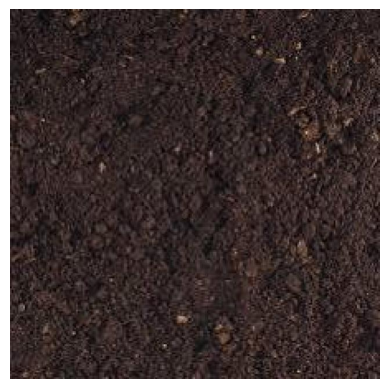

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

sample_path, sample_label = test_dataset.samples[0]
image = Image.open(sample_path).convert("RGB")
input_tensor = val_transform(image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    outputs = model(input_tensor)
    _, pred = torch.max(outputs, 1)

predicted_class = train_dataset.classes[pred.item()]
true_class = train_dataset.classes[sample_label]
print("Sample image:", sample_path)
print("Predicted class:", predicted_class)
print("True class:", true_class)

plt.imshow(image)
plt.axis("off")
plt.show()

## Predict on the Full Test Split
Run the model on all test images and collect predicted labels.

In [18]:
test_predictions = []
model.eval()
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Predicting test", leave=False):
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        test_predictions.extend(preds.cpu().tolist())

print("Collected predictions for test split:", len(test_predictions))
print("First 10 predicted labels:", test_predictions[:10])

Predicting test:   0%|          | 0/7 [00:00<?, ?it/s]

Collected predictions for test split: 204
First 10 predicted labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Visual Analytics for Test Predictions
Show a basic confusion matrix and class counts from the test split.


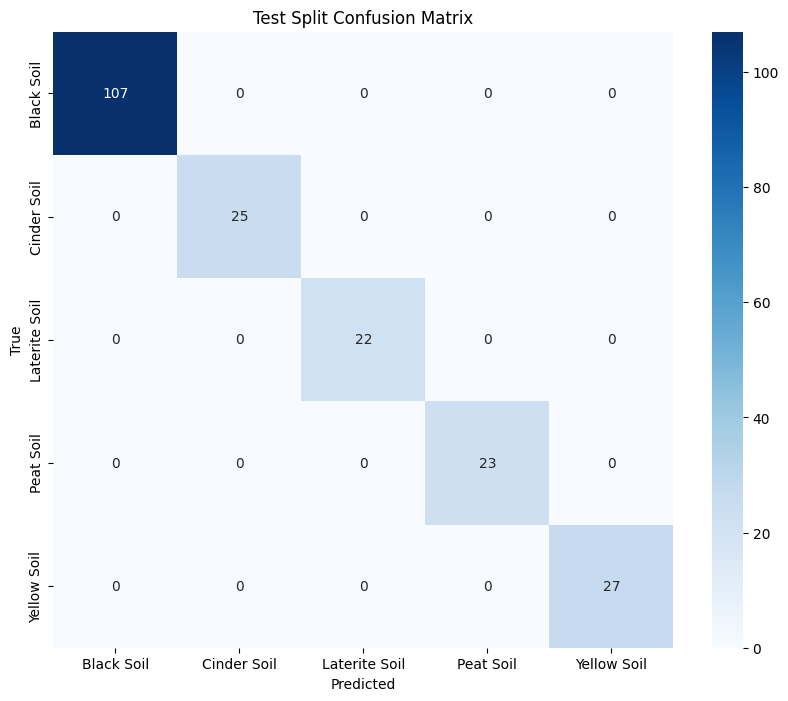

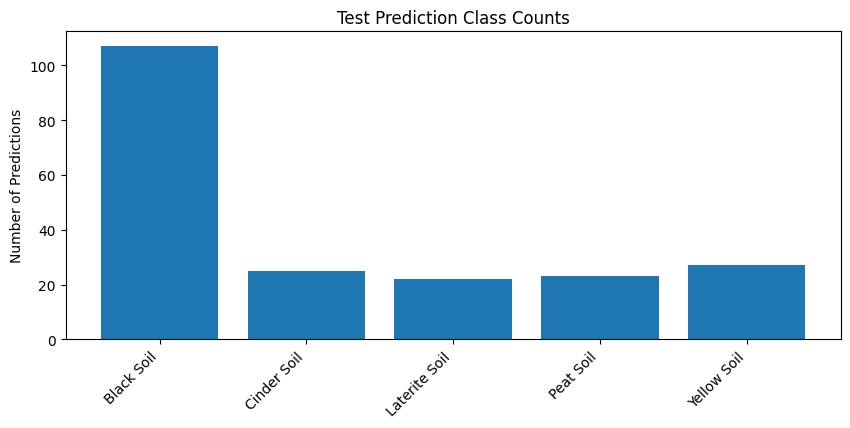

In [19]:
from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

true_labels = []
for _, labels in test_loader:
    true_labels.extend(labels.tolist())

cm = confusion_matrix(true_labels, test_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Split Confusion Matrix')
plt.show()

class_counts = np.bincount(test_predictions, minlength=len(train_dataset.classes))
plt.figure(figsize=(10, 4))
plt.bar(train_dataset.classes, class_counts)
plt.xticks(rotation=45, ha='right')
plt.title('Test Prediction Class Counts')
plt.ylabel('Number of Predictions')
plt.show()


## Save the Model Checkpoint
Save the trained model weights to a file for later reuse.

In [20]:
checkpoint_path = "soil_resnet50.pth"
torch.save(model.state_dict(), checkpoint_path)
print("Saved model to", checkpoint_path)

Saved model to soil_resnet50.pth
